<a href="https://colab.research.google.com/github/DanDC25/Statistical-Learning-with-Python/blob/main/%5BLab%203%5D%20DSA211_03_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA211 Statistical Learning
## Week 3 Lab: Regression Inference in Python

**Learning objectives:**
- Standardise numeric predictors and understand how this changes coefficient interpretation
- Extract and interpret the full inference output from `statsmodels` OLS
- Compute and visualise confidence intervals for coefficients on a common scale
- Compare confidence intervals and prediction intervals; visualise both bands
- Conduct a partial $F$-test for nested model comparison using `anova_lm`
- Apply the full inference workflow to test a substantive hypothesis on a real dataset

**Dataset:** Credit (ISLP companion dataset)  
**Tools:** `statsmodels`, `pandas`, `matplotlib`

---

## Part 0: EDA and Data Preparation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from scipy import stats

# Load dataset
url = 'https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/Credit.csv'
credit = pd.read_csv(url)
credit = credit.drop(columns='ID')
credit.index = range(1, len(credit) + 1)
print(credit.shape)
credit.head()

(400, 11)


,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Married,Ethnicity,Balance
1,14.891,3606,283,2,34,11,Male,No,Yes,Caucasian,333
2,106.025,6645,483,3,82,15,Female,Yes,Yes,Asian,903
3,104.593,7075,514,4,71,11,Male,No,No,Asian,580
4,148.924,9504,681,3,36,11,Female,No,No,Asian,964
5,55.882,4897,357,2,68,16,Male,No,Yes,Caucasian,331


Below I give the basic EDA steps without any interpretations. Please add them yourself.

In [ ]:
# Variable overview
credit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 1 to 400
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Income     400 non-null    float64
 1   Limit      400 non-null    int64  
 2   Rating     400 non-null    int64  
 3   Cards      400 non-null    int64  
 4   Age        400 non-null    int64  
 5   Education  400 non-null    int64  
 6   Gender     400 non-null    object 
 7   Student    400 non-null    object 
 8   Married    400 non-null    object 
 9   Ethnicity  400 non-null    object 
 10  Balance    400 non-null    int64  
dtypes: float64(1), int64(6), object(4)
memory usage: 34.5+ KB


**EDA Observation 1**: No missing data from any column in the data set. Each column has 400 entries.

In [ ]:
# Summary statistics
credit.describe().round(2)

,Income,Limit,Rating,Cards,Age,Education,Balance
count,400.00,400.00,400.00,400.00,400.00,400.00,400.00
mean,45.22,4735.60,354.94,2.96,55.67,13.45,520.02
std,35.24,2308.20,154.72,1.37,17.25,3.13,459.76
min,10.35,855.00,93.00,1.00,23.00,5.00,0.00
25%,21.01,3088.00,247.25,2.00,41.75,11.00,68.75
50%,33.12,4622.50,344.00,3.00,56.00,14.00,459.50
75%,57.47,5872.75,437.25,4.00,70.00,16.00,863.00
max,186.63,13913.00,982.00,9.00,98.00,20.00,1999.00


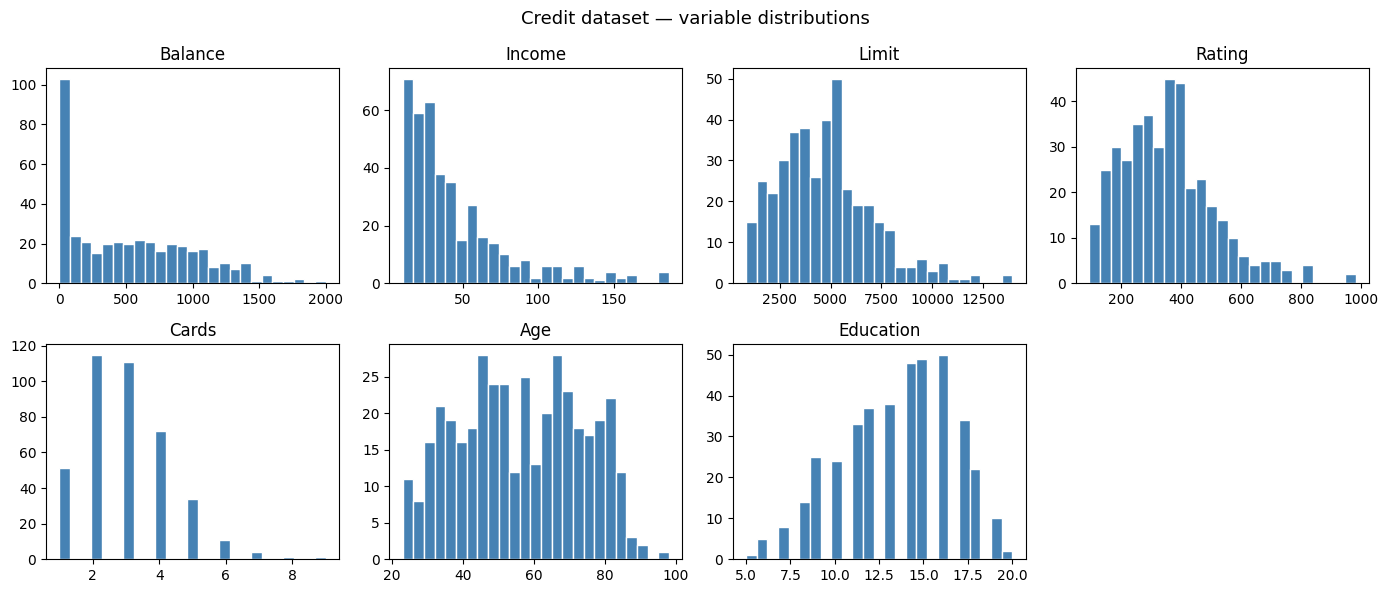

In [ ]:
# Distributions of numeric variables
num_vars = ['Balance', 'Income', 'Limit', 'Rating', 'Cards', 'Age', 'Education']
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()
for i, var in enumerate(num_vars):
    axes[i].hist(credit[var], bins=25, color='steelblue', edgecolor='white')
    axes[i].set_title(var)
axes[-1].set_visible(False)
fig.suptitle('Credit dataset — variable distributions', fontsize=13)
plt.tight_layout()
plt.show()

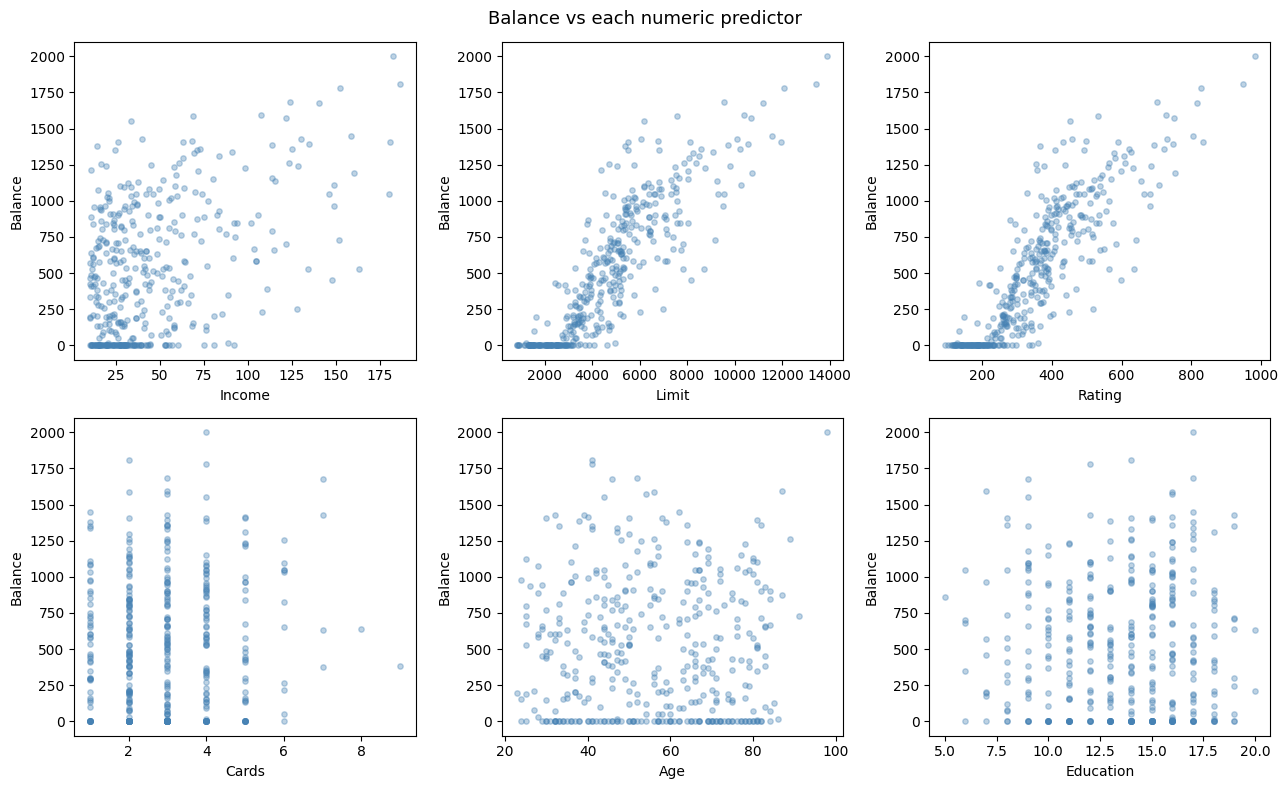

In [ ]:
# Balance vs each numeric predictor
predictors_num = ['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Education']
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()
for i, pred in enumerate(predictors_num):
    axes[i].scatter(credit[pred], credit['Balance'], alpha=0.35, s=15, color='steelblue')
    axes[i].set_xlabel(pred)
    axes[i].set_ylabel('Balance')
fig.suptitle('Balance vs each numeric predictor', fontsize=13)
plt.tight_layout()
plt.show()

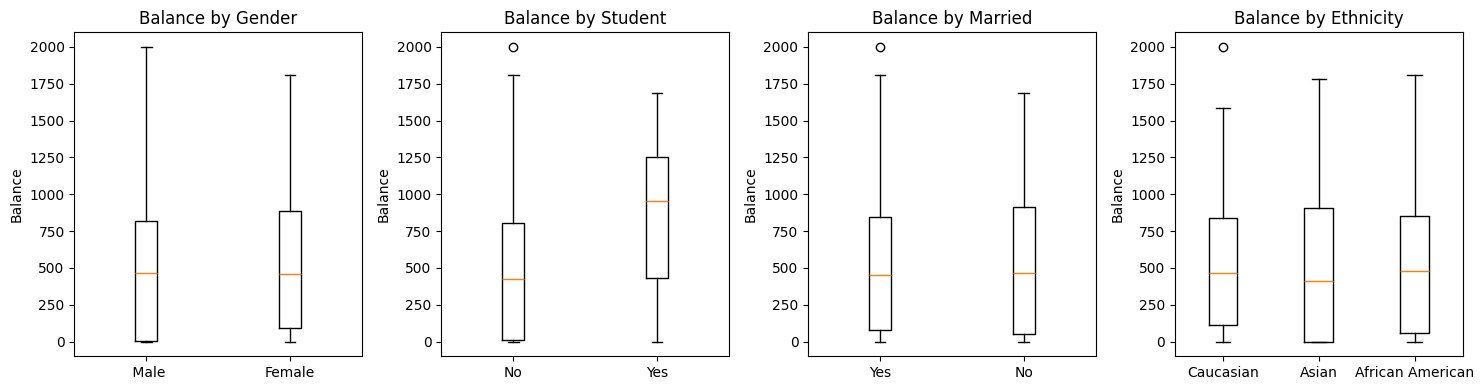

In [ ]:
# Balance by categorical variables
cat_vars = ['Gender', 'Student', 'Married', 'Ethnicity']
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for i, var in enumerate(cat_vars):
    groups = [credit.loc[credit[var] == v, 'Balance'] for v in credit[var].unique()]
    axes[i].boxplot(groups, tick_labels=credit[var].unique())
    axes[i].set_title(f'Balance by {var}')
    axes[i].set_ylabel('Balance')
plt.tight_layout()
plt.show()

> **EDA observations:** `Balance` has a strong positive association with both `Limit` and `Rating` (which are themselves highly correlated). Students carry substantially higher balances on average. `Income` is also *positively* associated with `Balance` on its own ($r = 0.46$). Note that sign reverses once we control for `Limit` in Part 1.

### Data preparation: encoding and standardisation

Before fitting any models, we prepare the dataset once:

1. **Encode** categorical predictors, done inside the model formula with `C()`
2. **Standardise** numeric predictors: subtract the column mean and divide by the column standard deviation

Standardising puts all numeric predictors on a common scale: each unit change becomes a one standard deviation change. This has two benefits:
- Coefficients are directly comparable across predictors regardless of original units
- A forest plot of CIs becomes meaningful as all estimates share the same axis

The indicator variables `C()` creates are left on their natural 0/1 scale. A one-unit change is already a natural quantity (non-student → student, unmarried → married, etc.).

Categorical predictors are encoded with `C()` in the formula, as in Lesson 2. Where inference is the point, this is the form to reach for. For example, `C()` keeps a categorical predictor as a single term, so a multi-level factor such as `Ethnicity` can be tested as a block rather than as separate indicators. Building the dummy columns by hand with `pd.get_dummies()` fits exactly the same model but it loses that grouping. Keep it for the sklearn pipelines in Week 7.

The cost is that `C()` produces long coefficient names: `C(Student)[T.Yes]` rather than `Student`. We define a small label map below and use it wherever a table or plot is meant to be read.

**Crucially, standardisation does not change $R^2$, $F$-statistics, or $p$-values** since we are merely rescaling the predictors, not fitting a different model.

In [ ]:
# Standardise numeric predictors (categoricals are encoded in the formula with C())
num_to_scale = ['Income', 'Limit', 'Age', 'Rating', 'Cards', 'Education']
credit_std = credit.copy() # duplicate first
credit_std[num_to_scale] = (credit[num_to_scale] - credit[num_to_scale].mean()) / credit[num_to_scale].std()

# Readable labels for the long names C() generates
label_map = {
    'C(Student)[T.Yes]':         'Student',
    'C(Married)[T.Yes]':         'Married',
    'C(Ethnicity)[T.Asian]':     'Ethnicity: Asian',
    'C(Ethnicity)[T.Caucasian]': 'Ethnicity: Caucasian',
}

# Verify
print('Mean and SD of standardised predictors (should be 0 and 1):')
print(credit_std[num_to_scale].agg(['mean', 'std']).round(4))

Mean and SD of standardised predictors (should be 0 and 1):
      Income  Limit  Age  Rating  Cards  Education
mean     0.0   -0.0  0.0     0.0   -0.0        0.0
std      1.0    1.0  1.0     1.0    1.0        1.0


All subsequent model fitting uses `credit_std`.

---

## Part 1: Reading the Inference Output

We fit a model predicting credit card balance from income, credit limit, age, and student status on the standardised scale.

### Demo 1.1 — Fitting the model and reading the summary

In [ ]:
model = smf.ols('Balance ~ Income + Limit + Age + C(Student)',
                data=credit_std).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                Balance   R-squared:                       0.949
Model:                            OLS   Adj. R-squared:                  0.949
Method:                 Least Squares   F-statistic:                     1845.
Date:                Sun, 06 Sep 2026   Prob (F-statistic):          4.93e-254
Time:                        13:53:59   Log-Likelihood:                -2423.4
No. Observations:                 400   AIC:                             4857.
Df Residuals:                     395   BIC:                             4877.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           477.4207      5.49

### Demo 1.2 — Interpreting the coefficients

**Intercept**: $\hat{\beta}_0$  
Expected balance when all standardised numeric predictors equal zero (i.e. at their means) and `Student = No`. Not of substantive interest.

**Income**:  
A one SD increase in income is associated with a decrease in average balance, holding Limit, Age, and Student status fixed. Look at the sign. In the EDA, `Income` and `Balance` were *positively* correlated ($r = 0.46$); here the coefficient is negative. Controlling for `Limit` flipped it. Income and Limit are strongly related ($r = 0.79$), and Limit is the dominant driver of Balance. Among people with the same credit limit, the higher earner carries the smaller balance. A predictor's marginal and partial effects can point in opposite directions, which is why you cannot read a multiple regression coefficient off a scatter plot. Highly significant ($p < 0.001$).

**Limit**:  
A one SD increase in credit limit is associated with a large increase in average balance. The largest numeric effect among the four predictors. Highly significant ($p < 0.001$).

**Age**:  
A one SD increase in age is associated with a small decrease in average balance. Borderline as the coefficient is not significant at 5% ($p = 0.086$) and marginal at 10%.

**Student**:  
Students carry on average substantially more balance than non-students, holding Income, Limit, and Age fixed. Not standardised as the coefficient is the difference between a student and a non-student in dollar terms. Highly significant ($p < 0.001$).

> **Note:** Because the numeric predictors are standardised, the coefficients for Income, Limit, and Age are now directly comparable in magnitude. We can read off relative importance from the table without worrying about units.

### Exercise 1.1

❓ **Question 1.1**

a) Verify the $t$-statistic for `Income` manually from the `coef` and `std err` columns. The $t$-statistic is negative, does this affect the $p$-value relative to what it would be if the $t$-statistic were positive but of the same magnitude? Explain.

b) b) The 95% CI for `Age` includes zero.

- Without calculating anything, what does that tell you about its $p$-value?
- The summary reports $p = 0.086$. Is `Age` significant at the 10% level?
- From your two answers, state the general relationship between a $(1-\alpha)$ CI and the two-sided $p$-value.
- Predict whether a 90% CI for `Age` contains zero, and roughly where its bounds will sit. You will check this in Part 2.

c) The raw coefficients for `Income` and `Limit` are $-7.83$ and $0.267$ respectively. A student concludes that `Income` has a much larger effect on `Balance` than `Limit`. What is wrong with this reasoning? How do the standardised coefficients resolve the problem?

In [ ]:
beta_news = model.params['Income']
se_news = model.bse['Income']
t_news = beta_news / se_news

df_resid = model.df_resid
p_two_sided = 2 * stats.t.sf(abs(t_news), df=df_resid)

print(f'Newspaper coefficient: {beta_news:.4f}')
print(f'Standard error:        {se_news:.4f}')
print(f't-statistic (manual):  {t_news:.4f}')
print(f'p-value (manual):      {p_two_sided:.4f}')

Newspaper coefficient: -276.1279
Standard error:        8.6585
t-statistic (manual):  -31.8911
p-value (manual):      0.0000


*Your answer here:*

a) (1)When manually verifying the t-statistic for income from the coefficient and standard error, the number is consistent with the stated number in the table. (2) If the t-statistic were to be postitive at the same magnitude, the p-value would not be affected as the two-tail test is already calculated using the absolute magnitude of the t-statistic.

b) When the 95% CI for Age includes zero, it tells me that the p-value is most likely to be > 0.05 as it is statistically insignificant, and the null hypothesis is failed to be rejected

To determine whether Age is significant at the 10% level, we must compare the p = 0.086 to the alpha (10%). Hence, Age is significant at 10% level as the calculated p-value is less than alpha.

As (1-alpha)CI increases, it's less likely for p-value to be smaller alpha. Consequently, the hypothesized null value would fall inside the confidence interval range, which "fail to reject" the null hypothesis.

c) The student most likely thought that income has a larger effect on balance than limit because of the magnitude of the coefficient. However, the student fails to realize that the magnitude of the coefficient could be dependent on the data itself - if the data points themselves are large, then it is, without a doubt, that the coefficient would also be large. Standardized coefficients would resolve this problem as they account for large data-points and keep all datapoints under the same "size".

I predict that with a 90% CI of *Age*, the boundaries would still include a 0 and would sit at [-15, 1]

---

## Part 2: Confidence Intervals for Coefficients

### Demo 2.1 — Extracting CIs and producing a forest plot

In [ ]:
# Extract 95% confidence intervals
ci_95 = model.conf_int(alpha=0.05)
ci_95.columns = ['lower', 'upper']
ci_95.insert(0, 'estimate', model.params)
print('95% Confidence Intervals:')
print(ci_95.round(4))

95% Confidence Intervals:
                   estimate     lower     upper
Intercept          477.4207  466.6270  488.2143
C(Student)[T.Yes]  425.9432  391.7655  460.1209
Income            -276.1279 -293.1504 -259.1055
Limit              616.5811  599.7418  633.4205
Age                 -9.1277  -19.5677    1.3124


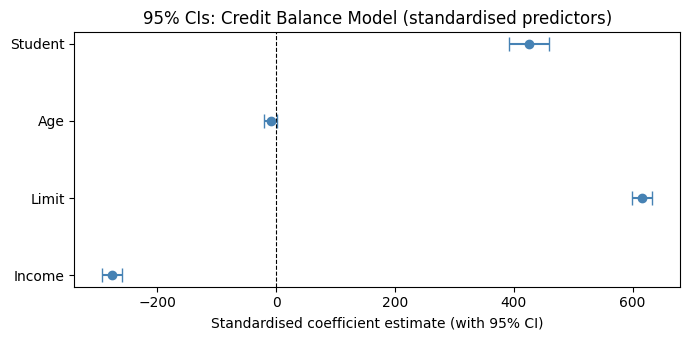

In [ ]:
# Forest plot — interpretable because all numeric predictors are standardised
predictors_plot = ['Income', 'Limit', 'Age', 'C(Student)[T.Yes]']
plot_labels = [label_map.get(p, p) for p in predictors_plot] # rename the varaible names

ests = ci_95.loc[predictors_plot, 'estimate']
lowers = ci_95.loc[predictors_plot, 'lower']
uppers = ci_95.loc[predictors_plot, 'upper']

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(x=ests,
            y=plot_labels,
            xerr=[ests - lowers, uppers - ests],
            fmt='o',
            color='steelblue',
            ecolor='steelblue',
            capsize=5,
            linewidth=1.5)
ax.axvline(0,
           color='black',
           linestyle='--',
           linewidth=0.8)
ax.set_xlabel('Standardised coefficient estimate (with 95% CI)')
ax.set_title('95% CIs: Credit Balance Model (standardised predictors)')
plt.tight_layout()
plt.show()

> **Note:** The forest plot is interpretable here because all numeric predictors are on a common scale. The student indicator is on a different scale (0/1 rather than SD units) but can still be plotted alongside for a rough comparison.

### Exercise 2.1

In [ ]:
### YOUR CODE HERE
# Task: compute the 90% CI for Age and check whether it excludes zero.
# Print the 90% and 95% CIs for Age side by side.

ci_90_age = model.conf_int(alpha=0.1)
ci_95_age = model.conf_int(alpha=0.05)
ci_90_age.columns = ['lower', 'upper']
age_lower_90 = ci_90_age.loc['Age', 'lower'].round(4)
age_upper_90 = ci_90_age.loc['Age', 'upper'].round(4)

print('90% Confidence Intervals:')
print(ci_90_age.loc[['Age',]].round(4))
print(f"Hence, the 90% CI for Age is [{age_lower_90}, {age_upper_90}]")


ci_95_age = model.conf_int(alpha=0.05)
ci_95_age.columns = ['lower', 'upper']
ci_95_age.insert(0, 'estimate', model.params)
#print('95% Confidence Intervals:')
#print(ci_95.round(4))


age_ci_90_renamed = ci_90_age.loc[['Age']].rename(columns={'estimate': 'estimate_90', 'lower': 'lower_90', 'upper': 'upper_90'})
age_ci_95_renamed = ci_95_age.loc[['Age']].rename(columns={'estimate': 'estimate_95', 'lower': 'lower_95', 'upper': 'upper_95'})

combined_cis = pd.concat([age_ci_90_renamed, age_ci_95_renamed], axis=1)

print('Confidence Intervals for Age (90% and 95%):')
print(combined_cis.round(4))

90% Confidence Intervals:
       lower   upper
Age -17.8829 -0.3724
Hence, the 90% CI for Age is [-17.8829, -0.3724]
Confidence Intervals for Age (90% and 95%):
     lower_90  upper_90  estimate_95  lower_95  upper_95
Age  -17.8829   -0.3724      -9.1277  -19.5677    1.3124


❓ **Question 2.1**

a) Does the 90% CI for `Age` exclude zero? Is this consistent with $p = 0.086$?

b) A wider CI reflects more uncertainty.

- What drives the width of a CI: sample size, variability of the predictor, residual variance, or the chosen confidence level?
- Which of these can the analyst control?

*Your answer here:*

a) The 90%CI for Age does exclude a zero as the interval range is within negative real numbers only. And yes, this is consistent with p = 0.086 (p-value < 0.1) as both method concludes that the null hypothesis is rejected with sufficient evidence.

b) I'm not sure about the other variables apart from **chosen confidence level**. Confidence level definitely drives the width of a CI as a lower confidence level equates to higher alpha, meaning the CI range is narrower.

As an analyst there are certain variables that are systematic and could not be changed such as the sample size, variability of the predictor, and residual variance as these are errors relating to the data set in which the analyst, unlike the data-collector, couldn't influence. The analyst can control chosen confidence level, which conveniently also the alpha

---

## Part 3: Prediction Intervals vs Confidence Intervals

### Demo 3.1 — Computing both intervals with `get_prediction`

In [ ]:
# Use simple regression for a clear 2D visualisation: Balance ~ Limit (standardised)
model_simple = smf.ols('Balance ~ Limit', data=credit_std).fit()

# Grid of standardised Limit values for smooth curves
limit_grid = pd.DataFrame({
    'Limit': np.linspace(credit_std['Limit'].min(), credit_std['Limit'].max(), 300)
})

# get_prediction returns CI for the mean response and PI for a new observation
preds = model_simple.get_prediction(limit_grid)
pred_df = preds.summary_frame(alpha=0.05)
pred_df['Limit'] = limit_grid['Limit'].values

pred_df[['Limit', 'mean', 'mean_ci_lower', 'mean_ci_upper',
          'obs_ci_lower', 'obs_ci_upper']].head().round(2)


,Limit,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,-1.68,-146.04,-191.00,-101.08,-607.45,315.37
1,-1.66,-138.54,-183.13,-93.96,-599.92,322.83
2,-1.64,-131.05,-175.26,-86.84,-592.39,330.29
3,-1.62,-123.55,-167.39,-79.71,-584.86,337.75
4,-1.61,-116.06,-159.53,-72.59,-577.32,345.21


`mean` refers to the predicted `balance` $(\hat{y})$.

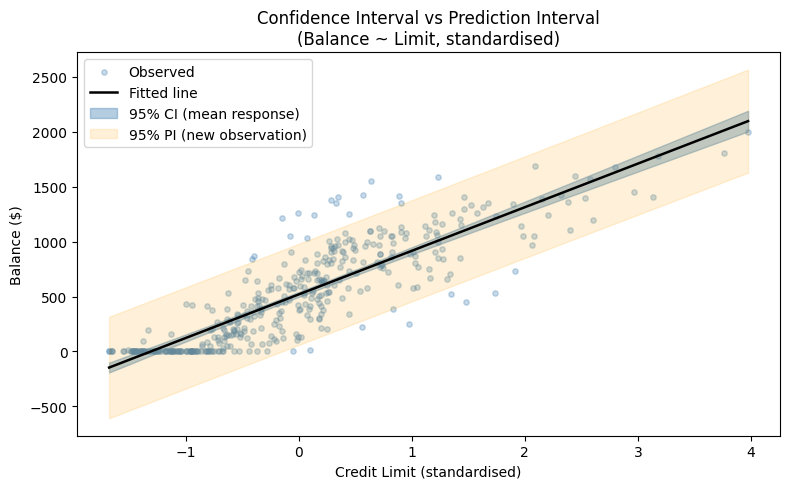

In [ ]:
# Visualise CI and PI together
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(credit_std['Limit'], # x-axis
           credit_std['Balance'],
           alpha=0.3,
           s=15,
           color='steelblue',
           label='Observed')
ax.plot(pred_df['Limit'], # x-axis
        pred_df['mean'], # fitted value
        color='black',
        linewidth=1.8,
        label='Fitted line')
ax.fill_between(pred_df['Limit'], # x-axis
                pred_df['mean_ci_lower'],
                pred_df['mean_ci_upper'],
                alpha=0.4,
                color='steelblue',
                label='95% CI (mean response)')
ax.fill_between(pred_df['Limit'], # x-axis
                pred_df['obs_ci_lower'],
                pred_df['obs_ci_upper'],
                alpha=0.15,
                color='orange',
                label='95% PI (new observation)')
ax.set_xlabel('Credit Limit (standardised)')
ax.set_ylabel('Balance ($)')
ax.set_title('Confidence Interval vs Prediction Interval\n(Balance ~ Limit, standardised)')
ax.legend()
plt.tight_layout()
plt.show()

### Exercise 3.1

In [ ]:
### YOUR CODE HERE
# Task: compute the 95% CI and PI at three points:
# the minimum, mean, and maximum of standardised Limit.
# Print a table showing: Limit value, fitted value, CI width, PI width.

limits = pd.DataFrame( {
    'Limit': [credit_std['Limit'].min(),
              credit_std['Limit'].mean(),
              credit_std['Limit'].max()]
})

preds = model_simple.get_prediction(limits)
df_intervals = preds.summary_frame(alpha=0.05)
df_intervals['Limit Values'] = limits
df_intervals['CI Width'] = df_intervals['mean_ci_upper'] - df_intervals['mean_ci_lower']
df_intervals['PI Width'] = df_intervals['obs_ci_upper'] - df_intervals['obs_ci_lower']

results = df_intervals[['Limit Values', 'mean', 'CI Width', 'PI Width']]
results.columns = ['Limit Value', 'Fitted Value', 'CI Width', 'PI Width']

results_renamed = results.rename(index={0: 'Minimum', 1: 'Mean', 2: 'Maximum'})
display(results_renamed.round(2))


,Limit Value,Fitted Value,CI Width,PI Width
Minimum,-1.68,-146.04,89.91,922.82
Mean,-0.00,520.02,45.92,919.58
Maximum,3.98,2095.20,188.49,937.57


❓ **Question 3.1**

a) Where are the CI and PI bands narrowest: near the minimum, mean, or maximum of Limit? Explain why this pattern occurs.

b) As $n \to \infty$, the CI width shrinks to zero. Does the PI width also shrink to zero? What does this tell us about the role of irreducible error in prediction?

*Your answer here:*

a) The CI and PI bands appear to be the narrowest near the mean. Near the mean of the data, there are more data points which allows the model to be stable. In other words, at the center, adding an additional data point will not significantly influence the model because of its small weightage compared to a large number of data points already existing at that location. Compared to at the minimum and maximum (the extremes), perhaps the reason why the band widens is because the model is more susceptible and sensitive to "wobbles" because there are significantly less data points than compared to at the center.

b) I don't think that the PI width shrinks to zero as $n \to \infty$. This is because of PI's formula itself ($\beta_0 + \beta_1 x^* + \varepsilon^*$) where even as there are infinite amount of data points, the irreducible error remains. Hence, as $n \to \infty$ PI width would shrink until it's equal to ɛ, and would remain there regarldless of any increase in $n$.

This tells us that the irreducible error is vital in prediction because it acts as a baseline of errors that informs researchers of the **minimum error** each model has regardless of its complexities.


---

## Part 4: Partial $F$-test with `anova_lm`

### Demo 4.1 — Nested model comparison

In [ ]:
# Restricted model: Income + Limit only
model_restricted = smf.ols('Balance ~ Income + Limit',
                           data=credit_std).fit()

# Full model: adds Age and Student status
model_full = smf.ols('Balance ~ Income + Limit + Age + C(Student)',
                     data=credit_std).fit()

# Partial F-test: are Age and Student status jointly useful after Income and Limit?
# Note: always pass the restricted (smaller) model first, full (larger) model second.
print('Partial F-test: adding Age and Student status to Income + Limit model')
print(anova_lm(model_restricted, model_full))

Partial F-test: adding Age and Student status to Income + Limit model
   df_resid           ssr  df_diff       ss_diff           F        Pr(>F)
0     397.0  1.087083e+07      0.0           NaN         NaN           NaN
1     395.0  4.284947e+06      2.0  6.585885e+06  303.553879  1.403872e-80


Adding `Age` and student status jointly is highly significant ($F(2, 395) = 303.55$, $p < 0.001$). Together they explain substantial additional variation in balance beyond income and credit limit alone.

In [ ]:
# Compare RSS and R² side by side
comparison = pd.DataFrame({
    'Model': ['Restricted: Income + Limit', 'Full: + Age + Student'],
    'RSS': [model_restricted.ssr, model_full.ssr],
    'R²': [model_restricted.rsquared, model_full.rsquared],
    'Adj R²': [model_restricted.rsquared_adj, model_full.rsquared_adj],
    'df_resid': [int(model_restricted.df_resid), int(model_full.df_resid)]
})
print(comparison.round(4).to_string(index=False))

                     Model          RSS     R²  Adj R²  df_resid
Restricted: Income + Limit 1.087083e+07 0.8711  0.8705       397
     Full: + Age + Student 4.284947e+06 0.9492  0.9487       395


Adding `Age` and student status cuts the residual sum of squares from $1.087 \times 10^{7}$ to $4.285 \times 10^{6}$, about 61% of what the smaller model left unexplained. $R^2$ rises from 0.8711 to 0.9492.

The adjusted $R^2$ increases from 0.8705 to 0.9487. $R^2$ *always* rises when a predictor is added, so a rise in $R^2$ on its own is not evidence of a better model. Adjusted $R^2$ penalises for each extra parameter, and it rises here too, so the additional two predictors are justified.

Those two parameters are why `df_resid` falls from 397 to 395 and the partial $F$-test is:

$$F = \frac{(\text{RSS}_r - \text{RSS}_f)/(p-q)}{\text{RSS}_f/(n-p-1)} = \frac{6{,}585{,}883/2}{4{,}284{,}947/395} = 303.55$$

as reported above.

- $R^2$ and RSS describe *how much* better the fit is;
- the $F$-test decides *whether* the improvement is more than sampling noise.

### Exercise 4.1

In [ ]:
### YOUR CODE HERE
# Task: test whether adding Education to model_full provides a significant improvement.
# 1. Fit the extended model adding Education to Income + Limit + Age + C(Student).
# 2. Use anova_lm to run the partial F-test against model_full.
# 3. Print the anova_lm table.
# 4. Extract the t-statistic for Education from the extended model summary
#    and verify that F = t².


model_restricted = smf.ols('Balance ~ Income + Limit + Age + C(Student)',
                           data=credit_std).fit()

model_full = smf.ols('Balance ~ Income + Limit + Age + C(Student) + Education',
                     data=credit_std).fit()
print("Partial F-test is to examine if adding Education provides any additional explanatory power after the existing Income + Limit + Age + C(Student) ")
print("Partial F-test:")
print(anova_lm(model_restricted, model_full))
print("Adding Education appears to not be statistically significant in improving from model_restricted as model_full's (F(1,394) = 1.34389, p-value = 0.247069)")
print(model_full.summary().tables[1])

t_value = float(model_full.tvalues['Education'])
F = "F-statistic value is 1.34389"
t_value_square = round(t_value ** 2,6)

print(f'The {F} is equal to the rounded(6 decimals points) t-value square of {t_value_square}')

Partial F-test is to examine if adding Education provides any additional explanatory power after the existing Income + Limit + Age + C(Student) 
Partial F-test:
   df_resid           ssr  df_diff       ss_diff         F    Pr(>F)
0     395.0  4.284947e+06      0.0           NaN       NaN       NaN
1     394.0  4.270382e+06      1.0  14564.702327  1.343789  0.247069
Adding Education appears to not be statistically significant in improving from model_restricted as model_full's (F(1,394) = 1.34389, p-value = 0.247069)
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           477.2733      5.489     86.947      0.000     466.481     488.065
C(Student)[T.Yes]   427.4172     17.423     24.531      0.000     393.163     461.672
Income             -276.3215      8.656    -31.921      0.000    -293.340    -259.303
Limit               616.5875      8.562     72.01

❓ **Question 4.1**

a) What is the partial $F$-statistic and its $p$-value? What is your conclusion about `Education`?

b) Verify that $F = t^2$ for the single-predictor case. Why does this equivalence hold? (optional)

c) If you were selecting predictors by looking at individual $t$-tests one at a time, could you arrive at a different conclusion from a joint partial $F$-test? Describe a scenario where this would happen. (optional)

*Your answer here:*

a) The partial F-statistic is 1.34378 and its p-value is 0.247069 which is larger than 0.05. My conclusion is that the addition of Education does not provide significant explanatory power to the model and isn't useful to be added after the exisiting Income + Limit + Age + C(Student).

b) After verifying, the equivalance does hold.

c) Yes I believe that I would arrive at a different conclusion if I selected individual predictors by looking at individual t-tests compared to a joint F-test. If I do so, I would not view the joint effect of all predictors together due to multicollinearity. Specifically, f-test may recognize that a group of variables highly correlate and explain the same variation. Individual t-tests on the other hand would believe that each predictor is not significant on its own. Consequently, the strength of each predictor would be misled; although each predictor has low strenghts on its own (which t-tests recognizes), jointly, they have well explanatory power (which f-tests recognizes).

---

## Part 5: Testing a Substantive Hypothesis

**Research question:** After accounting for income and credit limit, do demographic characteristics such as age, student status, marital status, and ethnicity *jointly* predict credit card balance?

### Demo 5.1 — Setting up the models

In [ ]:
# Baseline model: financial predictors only
model_financial = smf.ols('Balance ~ Income + Limit', data=credit_std).fit()

# Extended model: adds demographic variables
# C(Ethnicity) enters as one term with two indicators; African American is the reference
# category (C() takes the alphabetically first level unless told otherwise)
model_demo = smf.ols(
    'Balance ~ Income + Limit + Age + C(Student) + C(Married) + C(Ethnicity)',
    data=credit_std
).fit()
print(model_demo.summary())


                            OLS Regression Results                            
Dep. Variable:                Balance   R-squared:                       0.949
Model:                            OLS   Adj. R-squared:                  0.948
Method:                 Least Squares   F-statistic:                     1050.
Date:                Sun, 06 Sep 2026   Prob (F-statistic):          1.67e-249
Time:                        13:54:01   Log-Likelihood:                -2422.7
No. Observations:                 400   AIC:                             4861.
Df Residuals:                     392   BIC:                             4893.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

### Exercise 5.1


1. H0: B(Age) = B(Student) = B(Married) = B(Ethnicity) = 0 ; H1: B(Age) != B(Student) != B(Married) != B(Ethnicity) != 0
In words:
H0: The person's age, status of being student or Married or of any type of race has no effect/influence on Balance
H1: The person's age, status of being student or Married or of any type of race has a non-zero effect on Balance

2.
print(anova_lm(model_financial, model_demo))
#F-statistic: 121.196234; Degrees of freedom: 392; p-value: 2.832174^-77. At 5 percent significance level, we reject the null hypothesis as there isn't sufficient evidence to state otherwise.

3. Demographic variables individually significant at 5%: Student. Demographic variables not individually significant at 5%: Ethnicity (Asian and Caucasian), Age, Married



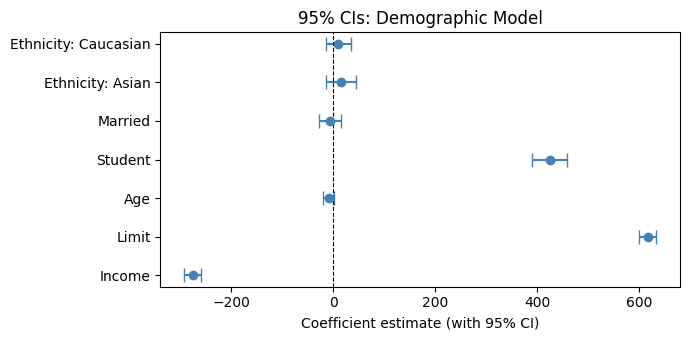

In [ ]:
### YOUR CODE HERE
# Task:
# 1. State H0 and H1 in words appropriate for this research question.
# 2. From the partial F-test output, identify the F-statistic, degrees of freedom,
#    and p-value. State your conclusion at the 5% significance level.
# 3. Examine the individual t-tests in model_demo. Which demographic variables
#    are individually significant at 5%? Which are not?
# 4. Produce a forest plot of the 95% CIs for all slope coefficients in model_demo.

print(f"""
1. H0: B(Age) = B(Student) = B(Married) = B(Ethnicity) = 0 ; H1: B(Age) != B(Student) != B(Married) != B(Ethnicity) != 0
In words:
H0: The person's age, status of being student or Married or of any type of race has no effect/influence on Balance
H1: The person's age, status of being student or Married or of any type of race has a non-zero effect on Balance

2.
print(anova_lm(model_financial, model_demo))
#F-statistic: 121.196234; Degrees of freedom: 392; p-value: 2.832174^-77. At 5 percent significance level, we reject the null hypothesis as there isn't sufficient evidence to state otherwise.

3. Demographic variables individually significant at 5%: Student. Demographic variables not individually significant at 5%: Ethnicity (Asian and Caucasian), Age, Married
""")

ci_demo_95 = model_demo.conf_int(0.05)
ci_demo_95.columns = ['lower', 'upper']
ci_demo_95.insert(0, 'estimate', model_demo.params)

predictors_plot = ['Income', 'Limit', 'Age', 'C(Student)[T.Yes]', 'C(Married)[T.Yes]', 'C(Ethnicity)[T.Asian]', 'C(Ethnicity)[T.Caucasian]']
plot_labels = [label_map.get(p, p) for p in predictors_plot]

ests = ci_demo_95.loc[predictors_plot, 'estimate']
lowers = ci_demo_95.loc[predictors_plot, 'lower']
uppers = ci_demo_95.loc[predictors_plot, 'upper']

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(x=ests,
            y=plot_labels,
            xerr=[ests - lowers, uppers - ests],
            fmt='o',
            color='steelblue',
            ecolor='steelblue',
            capsize=5,
            linewidth=1.5)
ax.axvline(0,
           color='black',
           linestyle='--',
           linewidth=0.8)
ax.set_xlabel('Coefficient estimate (with 95% CI)')
ax.set_title('95% CIs: Demographic Model')
plt.tight_layout()
plt.show()


❓ **Question 5.1** Can a joint $F$-test be statistically significant even when no individual $t$-test is significant at the same level? Explain why, and identify whether this situation might apply here.

*Your answer here:*

Yes I believe that a joint F-test can be statistically significant when no individual t-test is significant at the same level. This would occur because of the inherent nature of both tests (joint, and individual). For instance, in a data set where 2 predictors, alone, has little to none explanatory power because these two predictors are great at explaining variance jointly (perhaps they highly correlate with each other). When seperating each other, which is what t-tests do, they may not be significant; however, when joint (f-tests), these predictors provide great explanatory power and are statstically significant.

❓ **Question 5.2 (Synthesis)** Write a brief summary (~150 words) of your findings for a non-technical stakeholder. Your summary should:
- State the research question in plain language
- Report the key finding from the joint test
- Identify which specific demographic variables (if any) appear to matter independently
- Note at least one caveat about what this analysis can and cannot tell us
- Avoid technical jargon.

*Your answer here:*

It certainly isn't always satisfactory to look at your credit balance everytime the bank app is opened. Many believe that the harder one work, the more they earn, and eventually, a larger bank balance they receive. However, does "working hard" the sole factor in influencing bank balance? Can your education status, ethnic background, and age influence also? If so, to what extent do demographic variables such as age, martial status, race, and whether a person is a student or not determines their credit balance? By conducting a joint test, a statistical test that examines the influence of 2 or more variables — joint, it was found that ethnic backgrounds, martial status or even age do not influence your bank account balance. However, education background does. It's found to be statistically significant that having an education background is strongly linked with a higher account balance. Granted, this analysis does not infer that education **causes** higher account balance, eventhough the evidence strongly suggests so; the analysis provides the positive relationship between education background and account balance.


---

## Checklist

Before submitting, confirm:

- [ ] All demo cells run without errors
- [ ] Exercise 1.1 written answer complete (a, b, c)
- [ ] Exercise 2.1 coded and Question 2.1 answered (a, b)
- [ ] Exercise 3.1 coded and Question 3.1 answered (a, b)
- [ ] Exercise 4.1 coded (all four steps) and Question 4.1 answered (a, b, c)
- [ ] Exercise 5.1 coded (all four steps)
- [ ] Questions 5.1 and 5.2 answered in writing
- [ ] All plots have axis labels and titles